# Dream Emotion Classification — Assignment 2 Analysis Pipeline

This notebook builds the technical pipeline for my Results chapter: data preparation, SVM training/evaluation, emotion frequency analysis, and comparison against Freud/Jung/Hobson predictions.

**this is show  every output i get here (numbers, tables, plots) i will reference these directly in my Results and Discussion chapters. This is what my Assignment 1 feedback called 'traceability'.**


## 1. Setup

In [12]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Matplotlib is building the font cache; this may take a moment.
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sahartebyanian/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 2. Load data

In [13]:
DATA_PATH = "train.csv"  # change this if your file is elsewhere
df = pd.read_csv(DATA_PATH)
print("Rows:", len(df))
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'train.csv'

## 3. Extract dominant emotion label per dream

The `emotion` column stores Hall & Van de Castle codes (for example  `AP D`, `AN 1MKA, CO D`). I  extract
the set of HVDC emotion categories mentioned (AP, AN, HA, CO, SD) and take the **first-listed** one
as the dominant label for single-label classification. Dreams with no emotion code become the class
`NONE` (no emotion detected) — this matters for the frequency analysis (RQ1) even though it is not
one of the five HVDC categories itself.

Note the limitation this introduces (worth stating explicitly in  Discussion/Limitations,
consistent with the feedback about being transparent on methodological choices): about 29% of
emotion coded dreams contain more than one distinct category, and taking the first-listed one
discards secondary emotional content.

In [3]:
HVDC_CATEGORIES = ["AP", "AN", "HA", "CO", "SD"]

def extract_dominant_emotion(cell):
    if pd.isna(cell):
        return "NONE"
    codes = re.findall(r"\b(AP|AN|HA|CO|SD)\b", str(cell))
    if not codes:
        return "NONE"
    return codes[0]  # first-listed = dominant emotion

df["dominant_emotion"] = df["emotion"].apply(extract_dominant_emotion)
df["dominant_emotion"].value_counts()

dominant_emotion
NONE    16144
AP       4172
AN       2169
HA       2138
CO       2112
SD       1217
Name: count, dtype: int64

## 4. Clean the dream report text

This matches the four-stage preprocessing pipeline I have  already described in my Methodology
chapter: lowercase, remove punctuation/numbers, tokenise (handled implicitly by TF-IDF), remove
stop words (keeping emotionally significant terms).

In [ ]:
stop_words = set(stopwords.words("english"))

#this needs to  Keep a small set of emotionally significant words that a generic stopword list
# might otherwise strip whichi I  want to guarantee survive
KEEP_WORDS = {"not", "no", "never"}
stop_words = stop_words - KEEP_WORDS

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)      # strip leftover HTML line breaks
    text = re.sub(r"[^a-z\s]", " ", text)          # remove punctuation & numbers
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [w for w in text.split() if w not in stop_words]
    return " ".join(tokens)

df["clean_report"] = df["report"].apply(clean_text)
df[["report", "clean_report"]].head(3)

,report,clean_report
0,"The one at the Meads's house, where it's bigge...",one meads house bigger inside european village...
1,I'm at a family reunion in a large fine house ...,family reunion large fine house grounds maybe ...
2,I watch a plane fly past and shortly realize i...,watch plane fly past shortly realize low crash...


## 5. Build the modelling dataset

Decide here whether `NONE` should be a class the SVM predicts (a 6-class problem: detect *whether*
there is emotion and *which*), or whether you restrict the classifier to only the emotion   coded
dreams (a 5-class problem, closer to what assignmnt  Methodology chapter describes). Both are defensible;
the cell below builds both then I  can choose (or report both, which is even stronger evidence for
My  Results chapter).

In [ ]:
# drop empty reports
df = df[df["clean_report"].str.len() > 0].reset_index(drop=True)

# Option A: 5-class problem — only dreams with a coded Emotion
df_5class = df[df["dominant_emotion"] != "NONE"].reset_index(drop=True)

# Option B: 6-class problem — includes NONE
df_6class = df.copy()

print("5-class dataset size:", len(df_5class))
print(df_5class["dominant_emotion"].value_counts())
print()
print("6-class dataset size:", len(df_6class))
print(df_6class["dominant_emotion"].value_counts())

5-class dataset size: 11808
dominant_emotion
AP    4172
AN    2169
HA    2138
CO    2112
SD    1217
Name: count, dtype: int64

6-class dataset size: 27951
dominant_emotion
NONE    16143
AP       4172
AN       2169
HA       2138
CO       2112
SD       1217
Name: count, dtype: int64


## 6. TF-IDF + SVM training function

This is written as a reusable function then could  run it once for the 5-class dataset and once for
the 6-class dataset, and directly compare — useful, traceable evidence for your Results chapter.

In [6]:
def run_svm_pipeline(data, label_col="dominant_emotion", text_col="clean_report", test_size=0.2):
    X = data[text_col]
    y = data[label_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )

    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    clf = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000)
    clf.fit(X_train_tfidf, y_train)

    y_pred = clf.predict(X_test_tfidf)

    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0
    )

    print("Accuracy:", round(acc, 4))
    print("Macro Precision:", round(precision, 4))
    print("Macro Recall:", round(recall, 4))
    print("Macro F1:", round(f1, 4))
    print()
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    plt.title("Confusion Matrix")
    plt.show()

    return clf, vectorizer, {
        "accuracy": acc, "precision": precision, "recall": recall, "f1": f1
    }

## 7. Run: 5-class model

=== 5-CLASS MODEL (emotion-coded dreams only) ===


Accuracy: 0.6812
Macro Precision: 0.657
Macro Recall: 0.6601
Macro F1: 0.6585

              precision    recall  f1-score   support

          AN       0.70      0.74      0.72       434
          AP       0.74      0.73      0.73       835
          CO       0.64      0.63      0.64       422
          HA       0.67      0.67      0.67       428
          SD       0.53      0.54      0.53       243

    accuracy                           0.68      2362
   macro avg       0.66      0.66      0.66      2362
weighted avg       0.68      0.68      0.68      2362



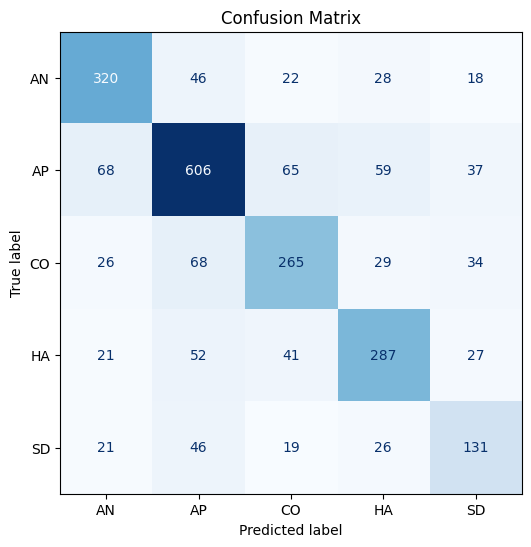

In [7]:
print("=== 5-CLASS MODEL (emotion-coded dreams only) ===")
clf_5, vec_5, metrics_5 = run_svm_pipeline(df_5class)

## 8. Run: 6-class model (includes NONE)

=== 6-CLASS MODEL (includes NONE) ===


Accuracy: 0.7548
Macro Precision: 0.6218
Macro Recall: 0.6195
Macro F1: 0.6201

              precision    recall  f1-score   support

          AN       0.64      0.68      0.66       434
          AP       0.67      0.60      0.63       835
          CO       0.59      0.54      0.56       422
          HA       0.56      0.57      0.56       428
        NONE       0.86      0.88      0.87      3229
          SD       0.42      0.44      0.43       243

    accuracy                           0.75      5591
   macro avg       0.62      0.62      0.62      5591
weighted avg       0.75      0.75      0.75      5591



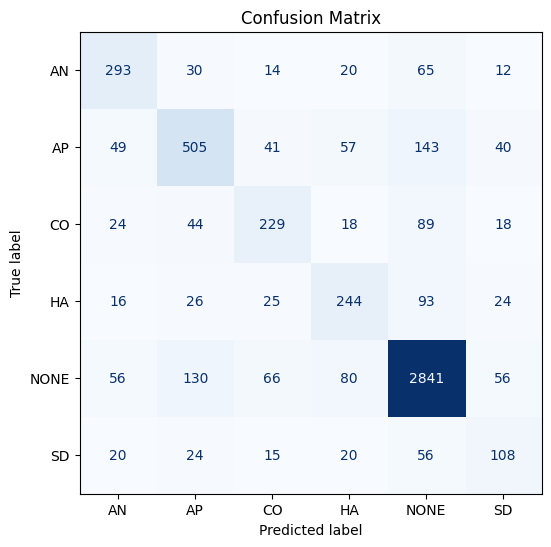

In [8]:
print("=== 6-CLASS MODEL (includes NONE) ===")
clf_6, vec_6, metrics_6 = run_svm_pipeline(df_6class)

## 9. K-fold cross-validation (robustness check)

My Methodology chapter already commits to k-fold CV as a safeguard against overfitting given the
moderate dataset size. This cell reports it directly — quote these numbers in Results chapter.

In [9]:
def run_kfold(data, k=5, label_col="dominant_emotion", text_col="clean_report"):
    X_text = data[text_col]
    y = data[label_col]
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X = vectorizer.fit_transform(X_text)
    clf = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(clf, X, y, cv=skf, scoring="f1_macro")
    print(f"{k}-fold macro F1 scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))
    return scores

print("5-class k-fold:")
scores_5 = run_kfold(df_5class)
print()
print("6-class k-fold:")
scores_6 = run_kfold(df_6class)

5-class k-fold:


5-fold macro F1 scores: [0.6564 0.6521 0.6502 0.6527 0.6465]
Mean: 0.6516 | Std: 0.0032

6-class k-fold:


5-fold macro F1 scores: [0.6296 0.6154 0.6216 0.6215 0.6212]
Mean: 0.6218 | Std: 0.0045


## 10. Emotion frequency distribution (answers RQ1)

This is the core evidence for comparing against Freud, Jung, and Hobson & McCarley.

dominant_emotion
No emotion coded    57.75
Apprehension        14.93
Anger                7.76
Happiness            7.65
Confusion            7.56
Sadness              4.35
Name: proportion, dtype: float64


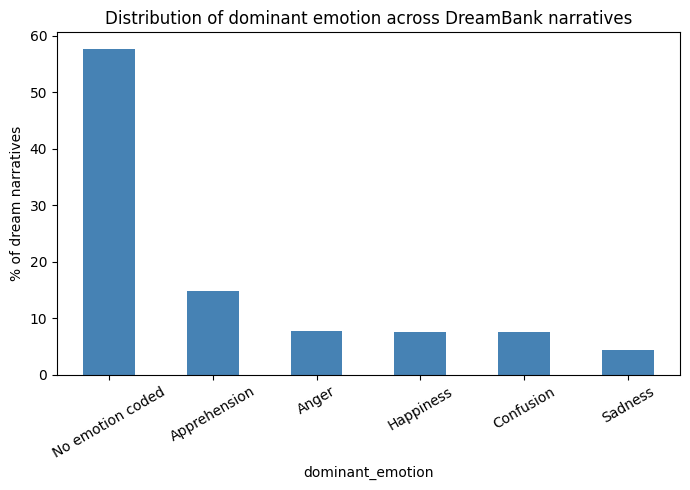


Among emotion-coded dreams only:
dominant_emotion
Apprehension    35.33
Anger           18.37
Happiness       18.11
Confusion       17.89
Sadness         10.31
Name: proportion, dtype: float64


In [10]:
label_names = {
    "AP": "Apprehension", "AN": "Anger", "HA": "Happiness",
    "CO": "Confusion", "SD": "Sadness", "NONE": "No emotion coded"
}

dist = df["dominant_emotion"].value_counts(normalize=True).rename(index=label_names) * 100
print(dist.round(2))

fig, ax = plt.subplots(figsize=(7, 5))
dist.sort_values(ascending=False).plot(kind="bar", ax=ax, color="steelblue")
ax.set_ylabel("% of dream narratives")
ax.set_title("Distribution of dominant emotion across DreamBank narratives")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("emotion_distribution.png", dpi=200)
plt.show()

# Among ONLY emotion-coded dreams (excludes NONE) — useful for testing H1 directly
dist_coded = df_5class["dominant_emotion"].value_counts(normalize=True).rename(index=label_names) * 100
print("\nAmong emotion-coded dreams only:")
print(dist_coded.round(2))

## 11. Feature importance (interpretability — supports  SVM justification)

Because of argumnet  for SVM over BERT partly on interpretability grounds, this cell extracts the
top TF-IDF terms driving each class's decision boundary. This is strong, concrete evidence for
the  Discussion chapter evidnce and directly answers the feedback point about traceability.

In [11]:
def top_terms_per_class(clf, vectorizer, top_n=15):
    feature_names = np.array(vectorizer.get_feature_names_out())
    for i, class_label in enumerate(clf.classes_):
        coefs = clf.coef_[i]
        top_idx = np.argsort(coefs)[-top_n:][::-1]
        print(f"\nTop terms for class '{class_label}':")
        print(", ".join(feature_names[top_idx]))

top_terms_per_class(clf_5, vec_5)


Top terms for class 'AN':
angry, annoyed, mad, frustrated, anger, angrily, disgusted, furious, annoying, disgust, jealous, irritated, pissed, aggravated, rage

Top terms for class 'AP':
worried, embarrassed, afraid, scared, nervous, concerned, uncomfortable, anxious, frightened, guilty, ashamed, fear, uneasy, panicked, scary

Top terms for class 'CO':
surprised, confused, amazed, shocked, surprise, wondered, startled, puzzled, wondering, perplexed, shock, questions perplexed, appalled, strange, confusing

Top terms for class 'HA':
happy, glad, pleased, enjoying, relieved, excited, thoughts happy, wonderful, delighted, pleasant, felt good, happily, thrilled, joy, fun

Top terms for class 'SD':
sad, disappointed, sorry, unhappy, crying, felt bad, lonely, depressed, sadness, cry, sobbing, cried, regret, distraught, hurt


## 12. Export tables for  write-up

This is traceable
record  this directly answers the Assignment 1 feedback about traceability of process and findings.

In [12]:
results_summary = pd.DataFrame([
    {"model": "5-class SVM", **metrics_5},
    {"model": "6-class SVM", **metrics_6},
])
results_summary.to_csv("results_summary.csv", index=False)
dist.to_csv("emotion_distribution_all.csv")
dist_coded.to_csv("emotion_distribution_coded_only.csv")

print(results_summary)
print("\nSaved: results_summary.csv, emotion_distribution_all.csv, emotion_distribution_coded_only.csv, emotion_distribution.png")

         model  accuracy  precision    recall        f1
0  5-class SVM  0.681202   0.657030  0.660139  0.658455
1  6-class SVM  0.754784   0.621832  0.619489  0.620104

Saved: results_summary.csv, emotion_distribution_all.csv, emotion_distribution_coded_only.csv, emotion_distribution.png


## 13. Baseline comparison (majority-class & stratified-random)

Added as a supplement to the pipeline above. Raw accuracy/F1 numbers are hard to interpret without
a reference point — a model can look 'good  ' just because one class dominates. This cell adds two
standard baselines so the SVM's performance can be reported as a genuine *improvement over chance*

In [13]:
from sklearn.dummy import DummyClassifier

def baseline_comparison(data, label_col='dominant_emotion', text_col='clean_report', test_size=0.2, tag=''):
    X = data[text_col]
    y = data[label_col]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_test_tfidf = vectorizer.transform(X_test)

    rows = []
    for strategy in ['most_frequent', 'stratified']:
        dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
        dummy.fit(X_train_tfidf, y_train)
        y_pred = dummy.predict(X_test_tfidf)
        acc = accuracy_score(y_test, y_pred)
        _, _, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
        rows.append({'model': f'{tag} baseline ({strategy})', 'accuracy': acc, 'f1_macro': f1})
    return pd.DataFrame(rows)

baseline_5 = baseline_comparison(df_5class, tag='5-class')
baseline_6 = baseline_comparison(df_6class, tag='6-class')

comparison = pd.concat([
    baseline_5,
    pd.DataFrame([{'model': '5-class SVM', 'accuracy': metrics_5['accuracy'], 'f1_macro': metrics_5['f1']}]),
    baseline_6,
    pd.DataFrame([{'model': '6-class SVM', 'accuracy': metrics_6['accuracy'], 'f1_macro': metrics_6['f1']}]),
], ignore_index=True)

print(comparison)
comparison.to_csv('baseline_comparison.csv', index=False)


                              model  accuracy  f1_macro
0  5-class baseline (most_frequent)  0.353514  0.104473
1     5-class baseline (stratified)  0.236664  0.196735
2                       5-class SVM  0.681202  0.658455
3  6-class baseline (most_frequent)  0.577535  0.122033
4     6-class baseline (stratified)  0.383116  0.172325
5                       6-class SVM  0.754784  0.620104


In [7]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
#defic
def grouped_cv(data, k=5, label_col="dominant_emotion", text_col="clean_report", group_col="id"):
    X, y, groups = data[text_col], data[label_col], data[group_col]
    print("Unique dreamers/series:", groups.nunique())

    cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    svm = make_pipeline(
        TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
        LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000),
    )
    scores = cross_val_score(svm, X, y, groups=groups, cv=cv, scoring="f1_macro")
    print("SVM grouped macro F1:", np.round(scores, 4),
          "| Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))

    for strategy in ["most_frequent", "stratified"]:
        dummy = make_pipeline(
            TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
            DummyClassifier(strategy=strategy, random_state=RANDOM_STATE),
        )
        s = cross_val_score(dummy, X, y, groups=groups, cv=cv, scoring="f1_macro")
        print(f"Baseline ({strategy}) macro F1 mean:", round(s.mean(), 4))
    return scores

print("=== 5-CLASS, GROUPED BY DREAMER ===")
grouped_5 = grouped_cv(df_5class)

ModuleNotFoundError: No module named 'sklearn'

In [9]:
import sklearn
print(sklearn.__version__)

ModuleNotFoundError: No module named 'sklearn'

In [10]:
import sys
print(sys.executable)

/Library/Developer/CommandLineTools/usr/bin/python3


In [11]:
import sys
!{sys.executable} -m pip install scikit-learn pandas numpy matplotlib nltk

12989.60s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 12.1 MB 1.5 MB/s eta 0:00:01
     |████████████████████████████████| 11.6 MB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 6.9 MB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 7.9 MB 1.5 MB/s eta 0:00:01
     |████████████████████████████████| 1.5 MB 2.9 MB/s eta 0:00:01
     |████████████████████████████████| 39.4 MB 1.3 MB/s eta 0:00:01
     |████████████████████████████████| 309 kB 3.5 MB/s eta 0:00:01
     |████████████████████████████████| 347 kB 3.2 MB/s eta 0:00:01
     |████████████████████████████████| 506 kB 1.0 MB/s eta 0:00:01
     |████████████████████████████████| 5.3 MB 1.6 MB/s eta 0:00:01     |█                               | 184 kB 1.6 MB/s eta 0:00:04
     |████████████████████████████████| 126 kB 3.2 MB/s eta 0:00:01
     |████████████████████████████████| 2.4 MB 995 kB/s eta 0:00:01
     |██████████████████████████████

In [ ]:
import sklearn
print(sklearn.__version__)

In [14]:
import sklearn

In [15]:
print(sklearn.__version__)

1.6.1


In [17]:
print(df_5class["id"].value_counts().head(10))

NameError: name 'df_5class' is not defined

In [18]:
import os
print(os.getcwd())
print(os.listdir())

/Users/sahartebyanian/Downloads
['IMG_3723.PNG', 'anydesk.dmg', '27055f34-e58c-4f67-937a-9535e9c32e39.JPG', 'IMG_3796.HEIC', 'Soft and Soulful – 60s Oldies That Touch the Heart🎶.mp4', 'googlechrome.dmg', 'Install Notion Apps-1.0.7-universal.zip', 'VisualStudioSetup (4).exe', 'OneDrive_2025-10-05.zip', 'Lip.Jpe', 'Visual Studio Code.app', 'photo_2026-06-21_11-55-25.jpg', 'CONL721 Week 2 - Lecture 1.docx', 'IMG_2410.heic', 'complete web page.png', 'P080113_21.23.jpg', 'VisualStudioSetup.exe', 'Paris-LDN .pdf', 'Greeting And Assistance', 'RDC1.pdf', 'IMG_2451.HEIC', 'IMG_3722.PNG', '2013-05-04 08.20.02.jpg', '001 Assignment 1-Design and Build a relational Database.pdf', 'Gone with the Wind 1939 .mp4', 'Telegram Desktop', 'FilmKio-1.5.3.pkg', 'IMG_2426.HEIC', 'dream_emotion_analysis_executed1.ipynb', 'از ذهن تا ماده داسون چرچ .pdf', 'IMG_5176.HEIC', 'body.css', 'IMG_2430.HEIC', 'VisualStudioSetup (1).exe alias', 'Algomath2.jpeg', '64400db6-974f-48e7-baab-c58a1526dc42.JPG', 'library4tar', '

In [19]:
df = pd.read_csv(r"C:\Users\YourName\Downloads\train.csv")   # Windows example

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\YourName\\Downloads\\train.csv'

In [20]:
DATA_PATH = "/Users/sahartebyanian/Downloads/train.xlsx"
df = pd.read_excel(DATA_PATH)
print("Rows:", len(df))
print(df.columns)
df.head()

ImportError: Missing optional dependency 'openpyxl'.  Use pip or conda to install openpyxl.

In [21]:
import sys
!{sys.executable} -m pip install openpyxl

14271.77s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 2.1 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.


In [23]:
DATA_PATH = "/Users/sahartebyanian/Downloads/train.xlsx"
df = pd.read_excel(DATA_PATH)

In [28]:
DATA_PATH = "/Users/sahartebyanian/Downloads/train.csv"
df = pd.read_csv(DATA_PATH)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sahartebyanian/Downloads/train.csv'

In [29]:
DATA_PATH = "/Users/sahartebyanian/Downloads/train.csv"
df = pd.read_csv(DATA_PATH)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sahartebyanian/Downloads/train.csv'

In [30]:
import pandas as pd
DATA_PATH = "/Users/sahartebyanian/Downloads/train.csv"
df = pd.read_excel(DATA_PATH)
print("Rows:", len(df))
print(df.columns)

ValueError: Excel file format cannot be determined, you must specify an engine manually.

In [31]:
import os
folder = "/Users/sahartebyanian/Downloads"
print([f for f in os.listdir(folder) if "train" in f.lower()])

['train.xlsx', 'train.csv']


In [32]:
import pandas as pd

DATA_PATH = "/Users/sahartebyanian/Downloads/PUT_EXACT_NAME_HERE"   # copy the name printed above

if DATA_PATH.lower().endswith(".csv"):
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_excel(DATA_PATH)

print("Rows:", len(df))
print(df.columns)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sahartebyanian/Downloads/PUT_EXACT_NAME_HERE'

In [33]:
import glob, os

home = os.path.expanduser("~")
matches = []
for ext in ("csv", "xlsx", "xls"):
    matches += glob.glob(f"{home}/Downloads/*train*.{ext}")
    matches += glob.glob(f"{home}/Desktop/*train*.{ext}")
    matches += glob.glob(f"{home}/Documents/**/*train*.{ext}", recursive=True)

for m in matches:
    print(m)

/Users/sahartebyanian/Downloads/train.csv
/Users/sahartebyanian/Downloads/train.xlsx


In [35]:
import pandas as pd

DATA_PATH = "/Users/sahartebyanian/Downloads/train.csv"   # replace with the path printed above

df = pd.read_csv(DATA_PATH) if DATA_PATH.lower().endswith(".csv") else pd.read_excel(DATA_PATH)
print("Rows:", len(df))
print(df.columns)

Rows: 27952
Index(['id', 'name', 'number', 'time', 'date', 'gender', 'age', 'report',
       'character', 'emotion'],
      dtype='object')


In [36]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier

def grouped_cv(data, k=5, label_col="dominant_emotion", text_col="clean_report", group_col="id"):
    X, y, groups = data[text_col], data[label_col], data[group_col]
    print("Unique dreamers/series:", groups.nunique())

    cv = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    svm = make_pipeline(
        TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
        LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000),
    )
    scores = cross_val_score(svm, X, y, groups=groups, cv=cv, scoring="f1_macro")
    print("SVM grouped macro F1:", np.round(scores, 4),
          "| Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))

    for strategy in ["most_frequent", "stratified"]:
        dummy = make_pipeline(
            TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
            DummyClassifier(strategy=strategy, random_state=RANDOM_STATE),
        )
        s = cross_val_score(dummy, X, y, groups=groups, cv=cv, scoring="f1_macro")
        print(f"Baseline ({strategy}) macro F1 mean:", round(s.mean(), 4))
    return scores

grouped_5 = grouped_cv(df_5class)
print(df_5class["id"].value_counts().head(10))

NameError: name 'df_5class' is not defined

In [1]:
import re
import numpy as np
import pandas as pd
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

RANDOM_STATE = 42

# 1. dominant emotion (first-listed HVDC code)
def extract_dominant_emotion(cell):
    if pd.isna(cell):
        return "NONE"
    codes = re.findall(r"\b(AP|AN|HA|CO|SD)\b", str(cell))
    return codes[0] if codes else "NONE"

df["dominant_emotion"] = df["emotion"].apply(extract_dominant_emotion)

# 2. clean text (same as the assignment)
stop_words = set(stopwords.words("english")) - {"not", "no", "never"}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return " ".join(w for w in text.split() if w not in stop_words)

df["clean_report"] = df["report"].apply(clean_text)
df = df[df["clean_report"].str.len() > 0].reset_index(drop=True)

# 3. five-class dataset
df_5class = df[df["dominant_emotion"] != "NONE"].reset_index(drop=True)
print("5-class size:", len(df_5class), "(should be 11808)")

# 4. grouped cross-validation by dreamer
X, y, groups = df_5class["clean_report"], df_5class["dominant_emotion"], df_5class["id"]
print("Unique dreamers/series:", groups.nunique())

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

svm = make_pipeline(
    TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
    LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=10000),
)
scores = cross_val_score(svm, X, y, groups=groups, cv=cv, scoring="f1_macro")
print("SVM grouped macro F1:", np.round(scores, 4),
      "| Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))

for strategy in ["most_frequent", "stratified"]:
    dummy = make_pipeline(
        TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2),
        DummyClassifier(strategy=strategy, random_state=RANDOM_STATE),
    )
    s = cross_val_score(dummy, X, y, groups=groups, cv=cv, scoring="f1_macro")
    print(f"Baseline ({strategy}) macro F1 mean:", round(s.mean(), 4))

print(df_5class["id"].value_counts().head(10))

NameError: name 'df' is not defined